# Task 1: Naive Bayes Classifier

## **1. Model Implementation and Training**

### **data preprocessing**

In [1]:
import pandas as pd
# Load the dataset
data_path = 'wdbc.data'
column_names = ["ID", "Diagnosis"] + [f"Feature_{i}" for i in range(1, 31)]
data = pd.read_csv(data_path, header=None, names=column_names)
data

,ID,Diagnosis,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,...,Feature_21,Feature_22,Feature_23,Feature_24,Feature_25,Feature_26,Feature_27,Feature_28,Feature_29,Feature_30
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [2]:
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Drop the ID column
data.drop(columns=["ID"], inplace=True)

# Encode the Diagnosis column
label_encoder = LabelEncoder()
data['Diagnosis'] = label_encoder.fit_transform(data['Diagnosis'])

# Split features and target
X = data.drop(columns=["Diagnosis"])
y = data['Diagnosis']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

- Drop the ID column: Because it is just a unique identifier for each patient and does not contain meaningful information for training a model.
- Encoding categorical data: The Diagnosis labels are categorical, so we need to transform 'M' into 1 (Malignant) and 'B' into 0 (Benign).
- Split Features and Target: We splited the data into features (X) and the target (y).
- Feature scaling: Different features might have varying ranges, which can negatively affect model performance. For example, a feature with a large range may dominate over others, skewing the results. Standardizes the features by removing the mean and scaling them to unit variance so that it has a mean of 0 and a standard deviation of 1.

### **Save the preprocessed data for future use**

In [3]:
# Creating a DataFrame with scaled features and encoded target variables
preprocessed_data = pd.DataFrame(X_scaled, columns=[f"Feature_{i}" for i in range(1, 31)])
preprocessed_data['Diagnosis'] = y.values

# Save pre-processed data to a CSV file
preprocessed_data.to_csv("preprocessed_wbdc_data.csv", index=False)

In [4]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets (70/30 split)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

### **Naive Bayes**

We use Gaussian Naive Bayes here because it's suitable for datasets with continuous numerical features, like the breast cancer dataset in this case, where each feature represents measurements (e.g., radius, texture, perimeter) that can reasonably follow a normal distribution.

In [5]:
from sklearn.naive_bayes import GaussianNB

# Initialize and train the Naive Bayes classifier
nb_classifier = GaussianNB()
nb_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = nb_classifier.predict(X_test)

## **2. Model Evaluation and Analysis**

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
# classification metrics: accuracy, precision, recall, F1-score
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred, target_names=['Benign', 'Malignant'])

print("Accuracy:", accuracy)
print("Classification Report:\n", classification_rep)

Accuracy: 0.935672514619883
Classification Report:
               precision    recall  f1-score   support

      Benign       0.94      0.95      0.95       108
   Malignant       0.92      0.90      0.91        63

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



We can see that the model's performance in identifying malignant samples is slightly lower. But, overall, the Naive Bayes classifier is well-suited for this task, yielding high accuracy and balanced metrics.

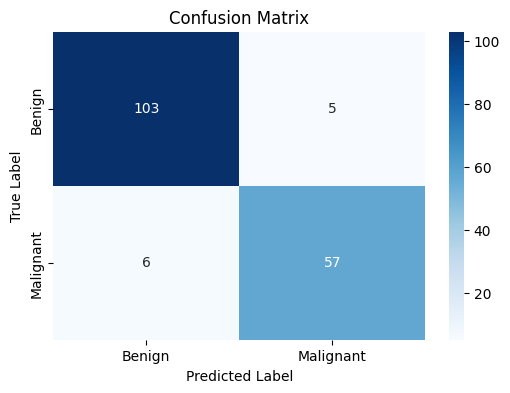

In [10]:
# confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

The model demonstrates high specificity, effectively identifying benign cases, as evidenced by only 5 benign samples misclassified as malignant. However, it shows a slight weakness in sensitivity for malignant cases, with 6 malignant samples misclassified as benign, indicating a tendency to miss some malignant diagnoses. Overall, the confusion matrix shows a generally balanced performance, although the model is somewhat better at recognizing benign cases than malignant ones. To improve its ability to detect malignant cases and reduce false negatives, feature selection, model tuning or a more complex model may needed.